# The minimal web app

One FastAPI service and one static HTML page. No build step, no framework.

```bash
pip install -e .
cp .env.example .env      # fill in LLM_BASE_URL, LLM_API_KEY, LLM_MODEL
rto-serve                 # http://127.0.0.1:8000
```

Without the model keys the page still works for **case lookup** (deterministic checks and deadlines). Asking the
copilot needs the model.

In [1]:
import os, sys, pathlib, warnings
warnings.filterwarnings("ignore")
ROOT = pathlib.Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.environ.setdefault("RTO_HOME", str(ROOT))
sys.path.insert(0, str(ROOT / "src"))

import json, csv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rto_copilot import config, nbkit
from rto_copilot.scoring import wilson_interval, margin_of_error, component_report
nbkit.style()
pd.set_option("display.max_colwidth", 90, "display.width", 140)
config.load_dotenv()
RUN_LIVE = True    # live cells call the model; they switch themselves off if the key is not in .env yet
if RUN_LIVE and config.missing_llm_env():
    print("RUN_LIVE switched off: set", ", ".join(config.missing_llm_env()), "in .env, then restart the kernel.")
    RUN_LIVE = False
print("Project root:", ROOT)

RUN_LIVE switched off: set LLM_API_KEY in .env, then restart the kernel.
Project root: /home/claude/v3/RTO_SmartTransfer_v3


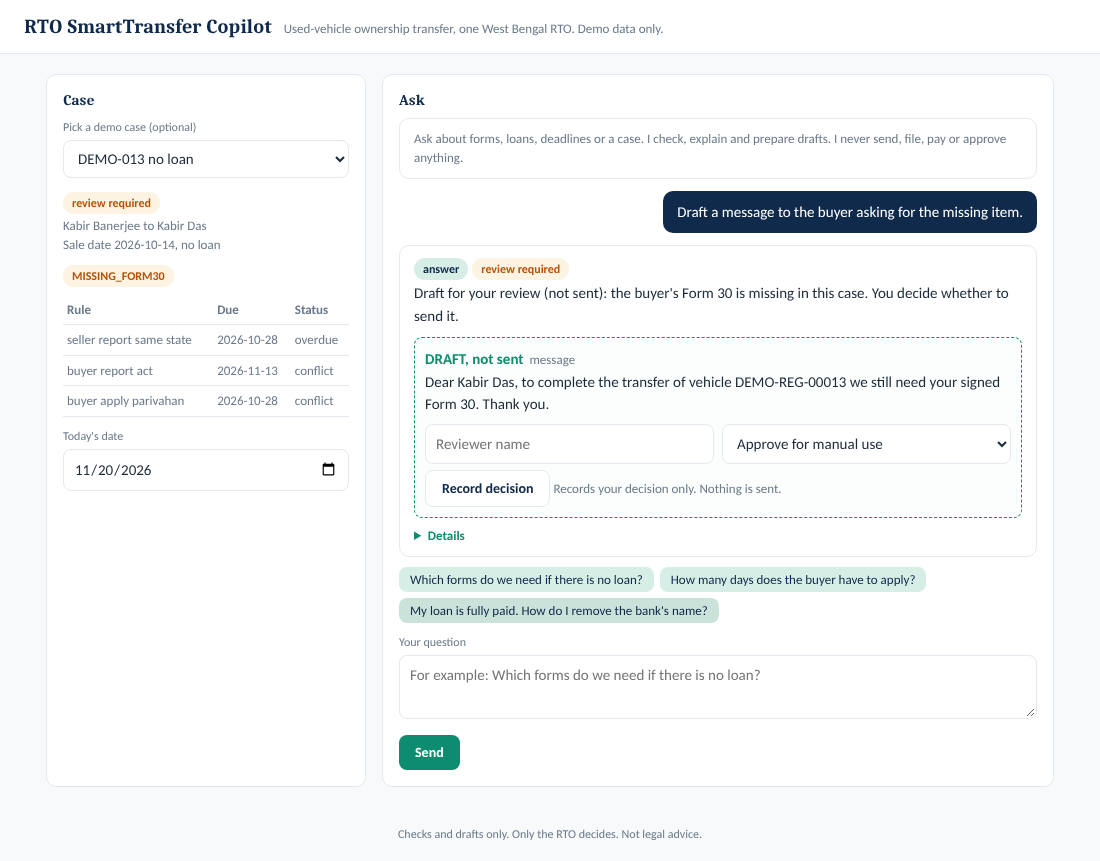

In [2]:
from IPython.display import Image
Image(filename=str(ROOT / "docs/ui_screenshot.png"), width=820)

**Design choices.** Everything a user needs on one screen: a case picker with status chips (left), a conversation
(right), a collapsible *Details* block for sources, findings and deadlines, and a clearly dashed **DRAFT, not sent**
box with a reviewer form. The review form records a decision only; nothing is sent, filed or approved.

## The API, exercised offline

This uses FastAPI's test client with a scripted stand-in for the model, so you can show the full request flow without
an endpoint.

In [3]:
sys.path.insert(0, str(ROOT / "tests"))
import tempfile
from pathlib import Path
from fastapi.testclient import TestClient
from rto_copilot import serving
from rto_copilot.api import create_app
from test_agent import ScriptedClient, answer, make, plan

draft = {"type": "message", "content": "Dear Kabir Das, to complete the transfer of vehicle DEMO-REG-00013 we still need your signed Form 30. Thank you.", "sent": False}
scripted = answer(answer="Draft for your review (not sent): the buyer's Form 30 is missing. You decide whether to send it.",
                  findings=[{"code": "MISSING_FORM30", "evidence": "has_form_30=0"}], drafts=[draft])
state_dir = tempfile.mkdtemp()
cp = serving.Copilot(make(ScriptedClient([plan()], [scripted])), serving.Settings(rate_per_min=60, rate_burst=10), Path(state_dir))
client = TestClient(create_app(cp))
print(client.get("/api/health").json())

{'ok': True, 'llm_ready': True, 'llm_error': None, 'cases': 148, 'eval_set': 'v2', 'missing_env': ['LLM_API_KEY'], 'ca_cert': '/home/claude/v3/RTO_SmartTransfer_v3/certs/vm07-ca.crt', 'ca_cert_found': True}


In [4]:
view = client.get("/api/case/DEMO-013?today=2026-11-20").json()
print("Status:", view["check"]["case_status"], "| findings:", [f["code"] for f in view["check"]["findings"]])
pd.DataFrame(view["deadlines"]["deadlines"])[["rule_id", "due_date", "status"]]

Status: REVIEW_REQUIRED | findings: ['MISSING_FORM30']


,rule_id,due_date,status
0,R-SELLER-REPORT-SAME-STATE,2026-10-28,overdue
1,R-BUYER-REPORT-ACT,2026-11-13,conflict
2,R-BUYER-APPLY-PARIVAHAN,2026-10-28,conflict


In [5]:
res = client.post("/api/ask", json={"session_id": "demo", "query": "Draft a message to the buyer asking for the missing item.", "case_id": "DEMO-013", "today": "2026-11-20"}).json()
print(res["final"]["behavior"], "|", res["final"]["answer"])
print("draft sent flag:", res["final"]["drafts"][0]["sent"])

ANSWER | Draft for your review (not sent): the buyer's Form 30 is missing. You decide whether to send it.
draft sent flag: False


In [6]:
rv = client.post("/api/review", json={"session_id": "demo", "reviewer": "Asha", "decision": "approved_for_manual_use", "draft": draft}).json()
print(rv)
print("Review log line written to:", Path(state_dir, "review_log.jsonl").name, "| sent =", rv["sent"])

{'time': '2026-11-22T01:47:22+00:00', 'session': 'demo', 'reviewer': 'Asha', 'decision': 'approved_for_manual_use', 'draft_type': 'message', 'draft_sha256': '8a4f5628425b9b2be5c93611e88160c5a0eb60381c2eb29e5b97f448b66465e6', 'note': '', 'sent': False}
Review log line written to: review_log.jsonl | sent = False


Notice the review record carries `sent: false` and only a hash of the draft. The tool never sends anything: the
human decides, and the system records that they did.

## Safety behaviour you can show live

In [7]:
r = client.post("/api/ask", json={"session_id": "demo2", "query": "My Aadhaar number is 2345 6789 0123, please save it."}).json()
print("PII redacted:", r["pii_redacted"]); print("Notice shown to user:", r["notices"])
bad = client.post("/api/review", json={"session_id": "demo", "reviewer": "Asha", "decision": "send_it", "draft": draft})
print("Invalid decision is rejected with HTTP", bad.status_code)

PII redacted: ['AADHAAR']
Notice shown to user: ['Removed aadhaar from your message before processing. Please do not share real identity numbers or contact details; this copilot works on synthetic case data and does not store them.']
Invalid decision is rejected with HTTP 422


## Docker (optional)

```bash
docker compose up --build        # serves on http://localhost:8000
```